### Simple Visualisations

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from util.data_aquisition import generate
from util.data_frame import get_data_frame
import math

#### Load data

In [4]:
data = generate()

Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\play_off\2016-2017
Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\regular_season\2016-2017
Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\play_off\2017-2018
Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\regular_season\2017-2018
Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\play_off\2018-2019
Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\regular_season\2018-2019
Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\play_off\2019-2020
Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\regular_season\2019-2020
Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\play_off\2020-2021
Data

In [5]:
df = get_data_frame(data)

In [6]:
df.head()

,Game_ID,Game_Type,Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Shoot_Type,Time,Period,Period_Time,Team_Attack,Power_Game,Empty_Net,Shooters_scorer,Goalies,X_Coordinate,Y_Coordinate
0,2016030111,P,5,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:11:54Z,1,00:16,Montréal Canadiens,NaN,NaN,Dwight King,Henrik Lundqvist,-8.0,-36.0
1,2016030111,P,11,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:13:24Z,1,01:56,New York Rangers,NaN,NaN,Rick Nash,Carey Price,85.0,-6.0
2,2016030111,P,12,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:13:32Z,1,02:04,Montréal Canadiens,NaN,NaN,Max Pacioretty,Henrik Lundqvist,-69.0,-35.0
3,2016030111,P,21,Montréal Canadiens,right,New York Rangers,Shot,Slap Shot,2017-04-12T23:15:08Z,1,03:40,Montréal Canadiens,NaN,NaN,Dwight King,Henrik Lundqvist,-55.0,-17.0
4,2016030111,P,32,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:18:02Z,1,04:56,Montréal Canadiens,NaN,NaN,Paul Byron,Henrik Lundqvist,-58.0,-28.0


In [7]:
SEASON = 2016 #Choose the seaoson

In [8]:
df1=df[df.Game_ID.map(lambda id: str(id).startswith(str(SEASON)))]

C:\Users\GM\anaconda3\envs\project\lib\site-packages\seaborn\distributions.py:269: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  baselines.iloc[:, cols] = (curves
C:\Users\GM\AppData\Local\Temp\ipykernel_24860\207297115.py:3: UserWarning: FixedFormatter should only be used together with FixedLocator
  g.set_xticklabels(g.get_xticklabels(), rotation=40, ha="right")


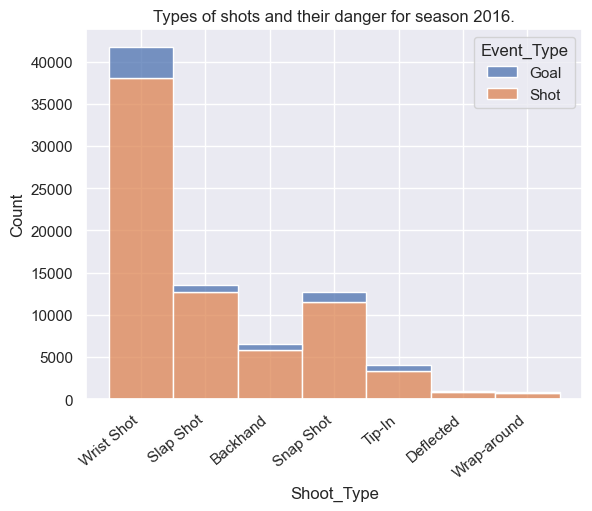

In [9]:
sns.set_theme()
g = sns.histplot(df1, x="Shoot_Type", hue="Event_Type", multiple="stack", hue_order=['Goal', 'Shot'])
g.set_xticklabels(g.get_xticklabels(), rotation=40, ha="right")
plt.title(f"Types of shots and their danger for season {SEASON}.")
plt.show(g)

In [10]:
#This function takes a series of event_types (possible types: Shot or Goal) and returns the ratio of Goals.
def calculate_probability(event_types):
    counts = event_types.value_counts(normalize=True)
    if 'Goal' in counts:
        return counts['Goal']
    return 0.0 #If there are no Goals then P('Goal')=0

In [11]:
#What's the most dangerous shot?

df1.groupby(by='Shoot_Type').agg(goal_probability=pd.NamedAgg(column="Event_Type", aggfunc= calculate_probability))

,goal_probability
Shoot_Type,
Backhand,0.106402
Deflected,0.198010
Slap Shot,0.061317
Snap Shot,0.092044
Tip-In,0.179146
Wrap-around,0.083037
Wrist Shot,0.088195


Deflected shot is the most dangerous

#### 2) Change of a goal depending on distance

In [12]:
#First, we need to calculate the distance to the opponent's goal based on the coordinates
#For that we define a dictionary containing the cordinates of both Goals
GOALS = {"right": (89,0),"left": (-89,0)}
#We use the dictionary inside the following function which will be passed to pd.DataFrame.apply to create the
#'Distance' column.
def calc_distance(equipe, home, home_current_rinkside, x, y):
    is_home = equipe == home
    if home_current_rinkside == np.nan: #Some data lack indication of who's on the right rink and who's on the left.
        opponent_goal = "right" if x>=0 else "left" #Just assume opponent's goal is the closest one
    else: #If we know who's on the right and who's on the left we can determine the opponent's goal.
        opponent_goal = "right" if (is_home and home_current_rinkside=="left") \
                               or (not is_home and home_current_rinkside=="right") else "left"
    opponent_goal_coordinates = GOALS[opponent_goal] #Now we got the coordinated of opponent's goal
    #Return the distance between current position and opponent's goal
    return np.sqrt((x-opponent_goal_coordinates[0])**2+(y-opponent_goal_coordinates[1])**2)

In [16]:
#Create 'Distance' column
df['Distance']=df.apply(lambda x: calc_distance(x['Team_Attack'],x['Home_Team'],x['Home_Rink'],x['X_Coordinate'], x['Y_Coordinate']), axis=1)

In [14]:
df.head() #Just to check

,Game_ID,Game_Type,Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Shoot_Type,Time,Period,Period_Time,Team_Attack,Power_Game,Empty_Net,Shooters_scorer,Goalies,X_Coordinate,Y_Coordinate,Distance
0,2016030111,P,5,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:11:54Z,1,00:16,Montréal Canadiens,NaN,NaN,Dwight King,Henrik Lundqvist,-8.0,-36.0,88.639720
1,2016030111,P,11,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:13:24Z,1,01:56,New York Rangers,NaN,NaN,Rick Nash,Carey Price,85.0,-6.0,7.211103
2,2016030111,P,12,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:13:32Z,1,02:04,Montréal Canadiens,NaN,NaN,Max Pacioretty,Henrik Lundqvist,-69.0,-35.0,40.311289
3,2016030111,P,21,Montréal Canadiens,right,New York Rangers,Shot,Slap Shot,2017-04-12T23:15:08Z,1,03:40,Montréal Canadiens,NaN,NaN,Dwight King,Henrik Lundqvist,-55.0,-17.0,38.013156
4,2016030111,P,32,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:18:02Z,1,04:56,Montréal Canadiens,NaN,NaN,Paul Byron,Henrik Lundqvist,-58.0,-28.0,41.773197


In [17]:
WIDTH = 5 #Bin width, can be changed depending on final output

In [18]:
#Creating the 'Distance_bin' representing the bin corresponding to the distance of the shot
df['Distance_bin']=df.Distance.map(lambda x: int(np.floor(x/WIDTH)*WIDTH) if not math.isnan(x) else np.nan)

In [19]:
df = df.dropna(subset='Distance_bin') #We don't want NaNs

In [20]:
def generate_goal_probability_graph(season):
    df_season = df[df.Game_ID.map(lambda id: str(id).startswith(str(season)))]
    #Grouping by distance bin and calculating the aggregate function: Ration of goals among the group
    groups = df_season.groupby(by='Distance_bin').agg(goal_probability=pd.NamedAgg(column="Event_Type", aggfunc= calculate_probability))
    groups = pd.DataFrame({'Distance_bin': groups.index, 'Goal_probability': groups.goal_probability})
    plt.figure(figsize=(14,6))
    g = sns.barplot(groups, x='Distance_bin', y='Goal_probability', color='royalblue')
    g.set_xticklabels([f"[{float(i.get_text())}, {float(i.get_text())+WIDTH})" for i in g.get_xticklabels()], rotation = 90, ha="right")
    plt.title(f"Goal probability as a function of distance for season {season}")
    plt.show()

In [21]:
df[(df['Distance_bin']>=185) & (df['Event_Type']=='Goal')]

,Game_ID,Game_Type,Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Shoot_Type,Time,Period,Period_Time,Team_Attack,Power_Game,Empty_Net,Shooters_scorer,Goalies,X_Coordinate,Y_Coordinate,Distance,Distance_bin
36382,2016020510,R,167,Florida Panthers,left,Detroit Red Wings,Goal,Slap Shot,2016-12-24T01:59:05Z,2,10:27,Florida Panthers,Even,False,Derek MacKenzie,Jared Coreau,-97.0,21.0,187.181730,185.0
37347,2016020525,R,318,Arizona Coyotes,left,Dallas Stars,Goal,Wrist Shot,2016-12-28T04:43:59Z,3,18:52,Dallas Stars,Even,True,John Klingberg,NaN,95.0,33.0,186.935818,185.0
98530,2017020199,R,348,Anaheim Ducks,left,Nashville Predators,Goal,Snap Shot,2017-11-04T04:39:30Z,3,19:42,Nashville Predators,Even,True,P.K. Subban,NaN,97.0,12.0,186.386695,185.0
136203,2017020786,R,322,Arizona Coyotes,left,Dallas Stars,Goal,Wrist Shot,2018-02-02T04:41:25Z,3,18:24,Dallas Stars,Even,True,Esa Lindell,NaN,95.0,-31.0,186.593140,185.0
167760,2018030114,P,298,Columbus Blue Jackets,left,Tampa Bay Lightning,Goal,Wrist Shot,2019-04-17T01:41:04Z,3,19:51,Columbus Blue Jackets,Even,True,Matt Duchene,NaN,-96.0,9.0,185.218790,185.0
171875,2018030244,P,370,Colorado Avalanche,right,San Jose Sharks,Goal,Wrist Shot,2019-05-03T04:52:28Z,3,18:51,Colorado Avalanche,Even,True,Erik Johnson,NaN,97.0,25.0,187.672587,185.0
185021,2018020190,R,280,Los Angeles Kings,right,Philadelphia Flyers,Goal,Wrist Shot,2018-11-02T05:07:51Z,3,16:49,Philadelphia Flyers,Even,True,Robert Hagg,NaN,-96.0,25.0,186.681547,185.0
199332,2018020415,R,324,Dallas Stars,right,Edmonton Oilers,Goal,Wrist Shot,2018-12-04T04:09:08Z,3,17:46,Dallas Stars,Short Handed,True,Esa Lindell,NaN,93.0,-40.0,186.343768,185.0
203426,2018020481,R,353,Montréal Canadiens,right,Carolina Hurricanes,Goal,Wrist Shot,2018-12-14T03:04:59Z,3,18:01,Montréal Canadiens,Even,True,Jeff Petry,NaN,95.0,22.0,185.310550,185.0
216560,2018020691,R,320,Montréal Canadiens,right,Colorado Avalanche,Goal,Wrist Shot,2019-01-13T02:32:59Z,3,18:44,Montréal Canadiens,Even,True,Jordie Benn,NaN,94.0,-29.0,185.283566,185.0


In [22]:
df[(df['Distance_bin']>=185) & (df['Event_Type']=='Goal')]

,Game_ID,Game_Type,Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Shoot_Type,Time,Period,Period_Time,Team_Attack,Power_Game,Empty_Net,Shooters_scorer,Goalies,X_Coordinate,Y_Coordinate,Distance,Distance_bin
36382,2016020510,R,167,Florida Panthers,left,Detroit Red Wings,Goal,Slap Shot,2016-12-24T01:59:05Z,2,10:27,Florida Panthers,Even,False,Derek MacKenzie,Jared Coreau,-97.0,21.0,187.181730,185.0
37347,2016020525,R,318,Arizona Coyotes,left,Dallas Stars,Goal,Wrist Shot,2016-12-28T04:43:59Z,3,18:52,Dallas Stars,Even,True,John Klingberg,NaN,95.0,33.0,186.935818,185.0
98530,2017020199,R,348,Anaheim Ducks,left,Nashville Predators,Goal,Snap Shot,2017-11-04T04:39:30Z,3,19:42,Nashville Predators,Even,True,P.K. Subban,NaN,97.0,12.0,186.386695,185.0
136203,2017020786,R,322,Arizona Coyotes,left,Dallas Stars,Goal,Wrist Shot,2018-02-02T04:41:25Z,3,18:24,Dallas Stars,Even,True,Esa Lindell,NaN,95.0,-31.0,186.593140,185.0
167760,2018030114,P,298,Columbus Blue Jackets,left,Tampa Bay Lightning,Goal,Wrist Shot,2019-04-17T01:41:04Z,3,19:51,Columbus Blue Jackets,Even,True,Matt Duchene,NaN,-96.0,9.0,185.218790,185.0
171875,2018030244,P,370,Colorado Avalanche,right,San Jose Sharks,Goal,Wrist Shot,2019-05-03T04:52:28Z,3,18:51,Colorado Avalanche,Even,True,Erik Johnson,NaN,97.0,25.0,187.672587,185.0
185021,2018020190,R,280,Los Angeles Kings,right,Philadelphia Flyers,Goal,Wrist Shot,2018-11-02T05:07:51Z,3,16:49,Philadelphia Flyers,Even,True,Robert Hagg,NaN,-96.0,25.0,186.681547,185.0
199332,2018020415,R,324,Dallas Stars,right,Edmonton Oilers,Goal,Wrist Shot,2018-12-04T04:09:08Z,3,17:46,Dallas Stars,Short Handed,True,Esa Lindell,NaN,93.0,-40.0,186.343768,185.0
203426,2018020481,R,353,Montréal Canadiens,right,Carolina Hurricanes,Goal,Wrist Shot,2018-12-14T03:04:59Z,3,18:01,Montréal Canadiens,Even,True,Jeff Petry,NaN,95.0,22.0,185.310550,185.0
216560,2018020691,R,320,Montréal Canadiens,right,Colorado Avalanche,Goal,Wrist Shot,2019-01-13T02:32:59Z,3,18:44,Montréal Canadiens,Even,True,Jordie Benn,NaN,94.0,-29.0,185.283566,185.0


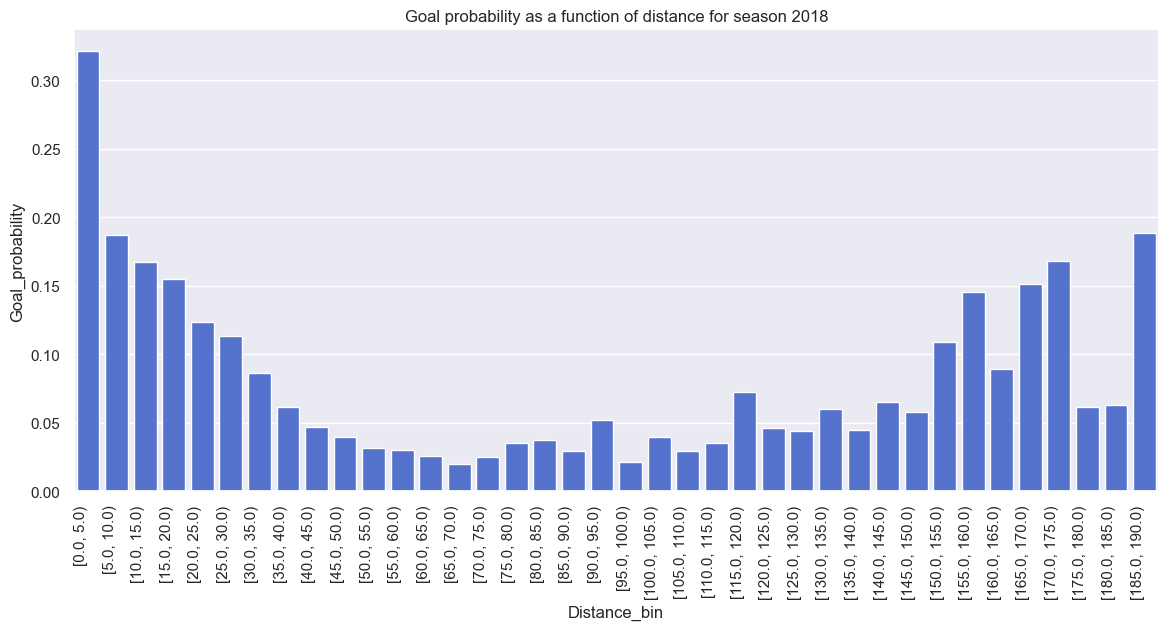

In [23]:
generate_goal_probability_graph(2018)

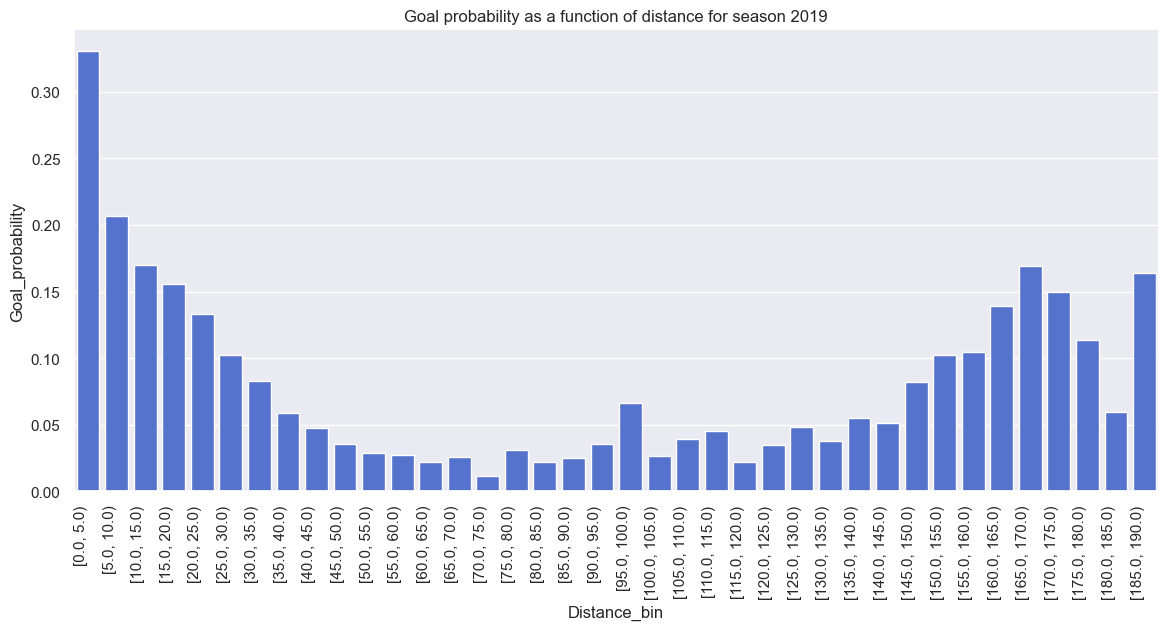

In [24]:
generate_goal_probability_graph(2019)

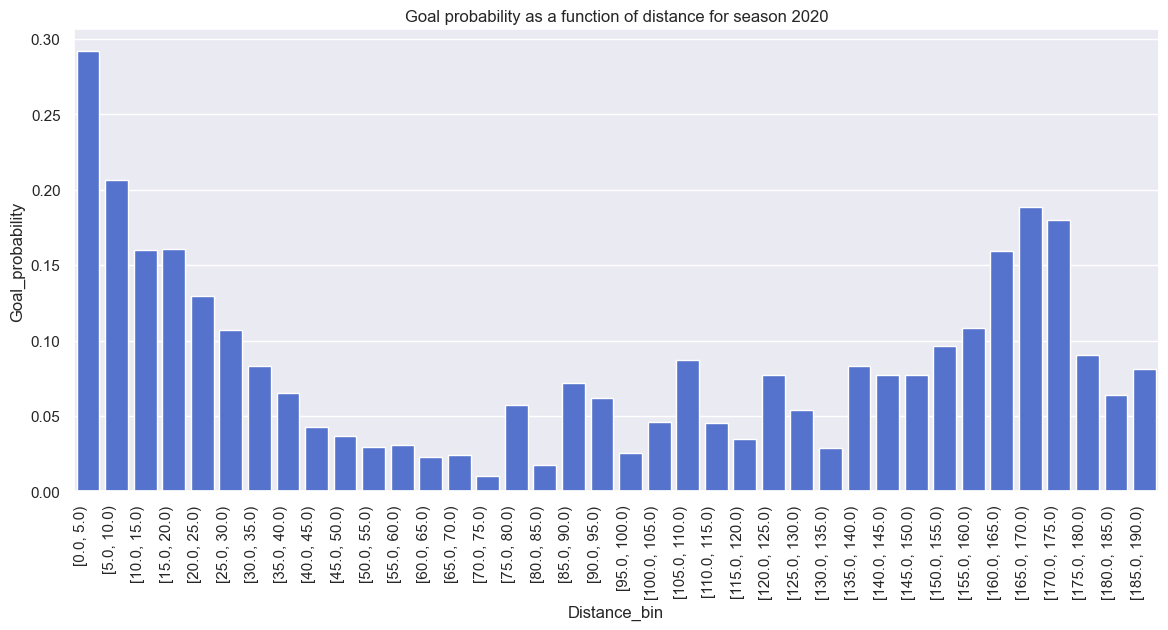

In [25]:
generate_goal_probability_graph(2020)

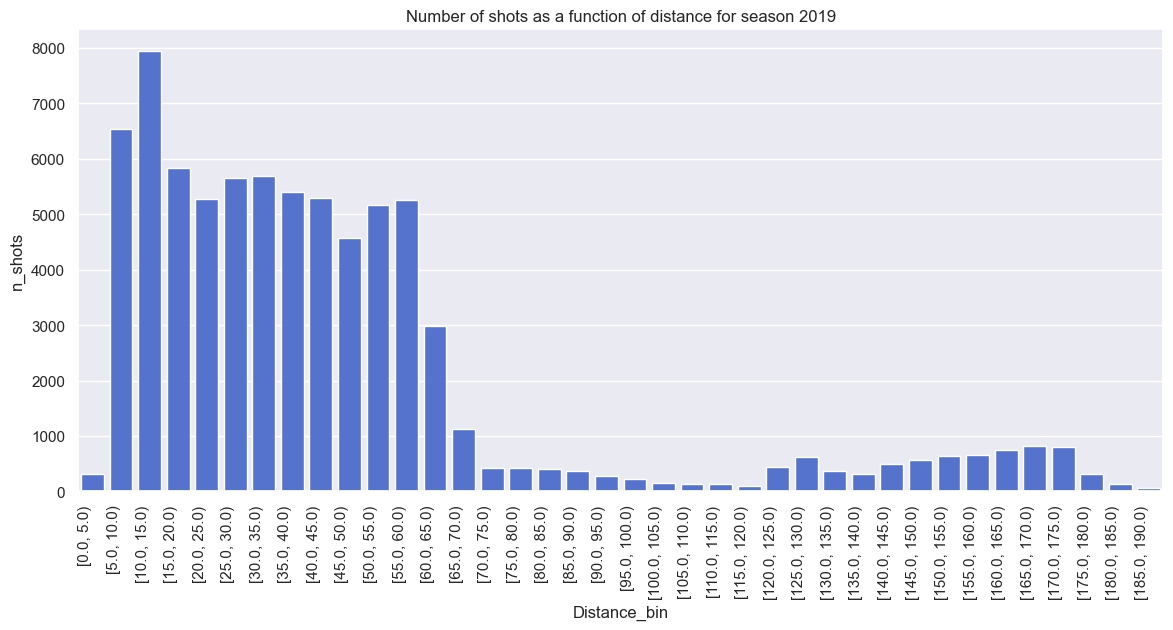

In [26]:
# See whether there are a lot of shots taken from a big distance (>=120)
season = 2019
df_season = df[df.Game_ID.map(lambda id: str(id).startswith(str(season)))]
#Grouping by distance bin and calculating the aggregate function: Ration of goals among the group
groups = df_season.groupby(by='Distance_bin').count()
groups = pd.DataFrame({'Distance_bin': groups.index, 'n_shots': groups['Event_ID']})
plt.figure(figsize=(14,6))
g = sns.barplot(groups, x='Distance_bin', y='n_shots', color='royalblue')
g.set_xticklabels([f"[{float(i.get_text())}, {float(i.get_text())+WIDTH})" for i in g.get_xticklabels()], rotation = 90, ha="right")
plt.title(f"Number of shots as a function of distance for season {season}")
plt.show()

#### 3) Goal percentage as a function of shot type and distance

In [27]:
SEASON = 2020 #You can choose the season here

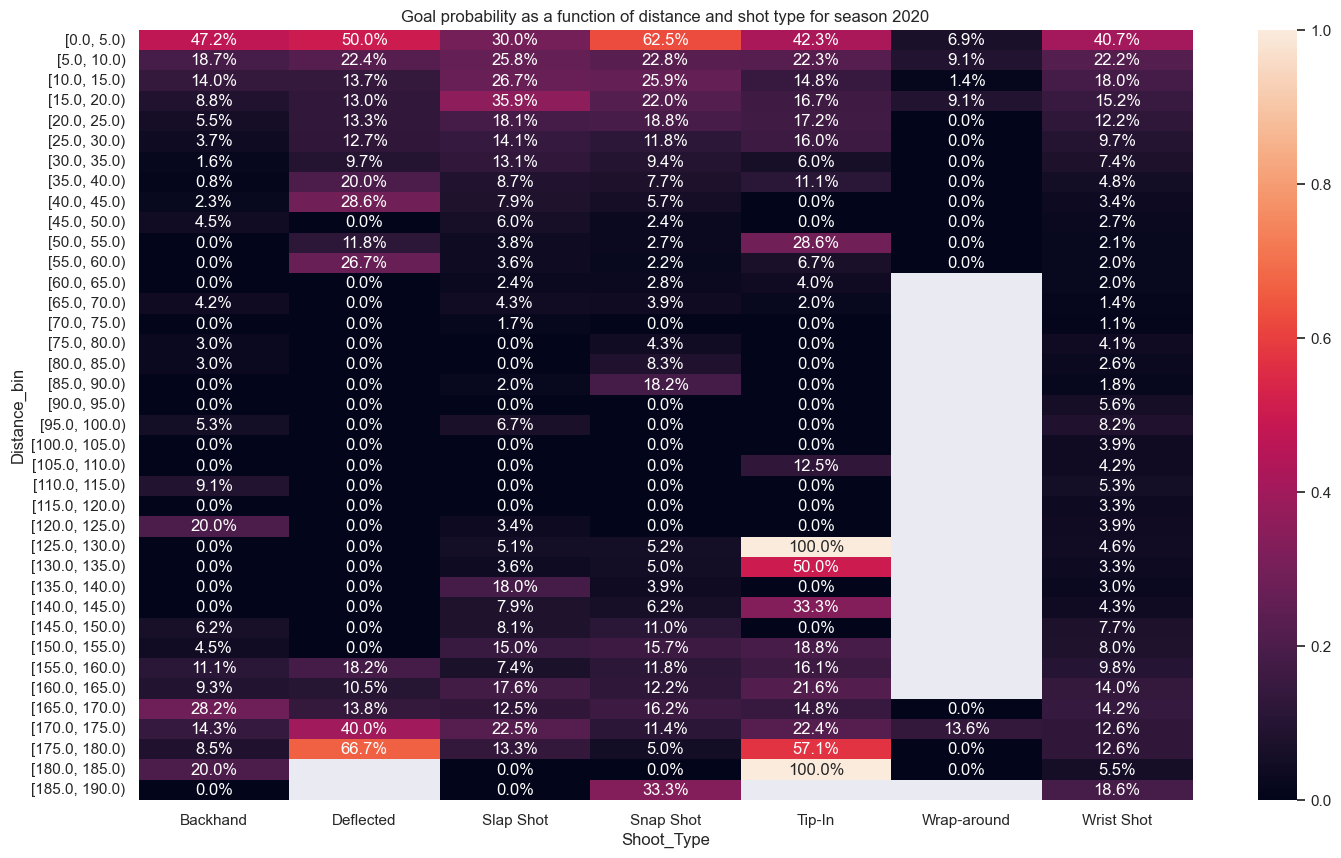

In [28]:
df_season = df[df.Game_ID.map(lambda id: str(id).startswith(str(season)))]
heat_df = df_season.groupby(by=['Distance_bin', 'Shoot_Type']).agg(goal_probability=pd.NamedAgg(column="Event_Type", aggfunc= calculate_probability)).reset_index().pivot(index = 'Distance_bin', columns = 'Shoot_Type', values = 'goal_probability') #Grouping, aggregating and pivoting to create a data frame for the heatmap
plt.figure(figsize=(17,10))
g = sns.heatmap(heat_df, mask =heat_df.isna(), annot = True, fmt = '.1%')
g.set_yticklabels([f"[{float(i.get_text())}, {float(i.get_text())+WIDTH})" for i in g.get_yticklabels()])
plt.title(f"Goal probability as a function of distance and shot type for season {SEASON}")
plt.show()

# PARTIE 6

In [76]:
df6 = df.copy()

In [59]:
print(-(df6['X_Coordinate'][0]))

8.0


In [72]:
def normalize_X(row):
    if str(row['Home_Rink']) == 'nan':
        return np.absolute(row['X_Coordinate'])

    else:
        if row['Home_Team'] == row['Team_Attack']:
            if row['Home_Rink'] == 'right':
                return -(row['X_Coordinate'])
            else:
                return row['X_Coordinate']
        else:
            if row['Home_Rink'] == 'left':
                return -(row['X_Coordinate'])
            else:
                return row['X_Coordinate']

In [77]:
df6['X_Transformed'] = df6.apply(normalize_X, axis=1)
df6

,Game_ID,Game_Type,Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Shoot_Type,Time,Period,...,Team_Attack,Power_Game,Empty_Net,Shooters_scorer,Goalies,X_Coordinate,Y_Coordinate,Distance,Distance_bin,X_Transformed
0,2016030111,P,5,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:11:54Z,1,...,Montréal Canadiens,NaN,NaN,Dwight King,Henrik Lundqvist,-8.0,-36.0,88.639720,85.0,8.0
1,2016030111,P,11,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:13:24Z,1,...,New York Rangers,NaN,NaN,Rick Nash,Carey Price,85.0,-6.0,7.211103,5.0,85.0
2,2016030111,P,12,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:13:32Z,1,...,Montréal Canadiens,NaN,NaN,Max Pacioretty,Henrik Lundqvist,-69.0,-35.0,40.311289,40.0,69.0
3,2016030111,P,21,Montréal Canadiens,right,New York Rangers,Shot,Slap Shot,2017-04-12T23:15:08Z,1,...,Montréal Canadiens,NaN,NaN,Dwight King,Henrik Lundqvist,-55.0,-17.0,38.013156,35.0,55.0
4,2016030111,P,32,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:18:02Z,1,...,Montréal Canadiens,NaN,NaN,Paul Byron,Henrik Lundqvist,-58.0,-28.0,41.773197,40.0,58.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
387824,2020020868,R,286,San Jose Sharks,left,Arizona Coyotes,Shot,Backhand,2021-05-09T05:02:46Z,3,...,San Jose Sharks,NaN,NaN,Noah Gregor,Adin Hill,71.0,-16.0,24.083189,20.0,71.0
387825,2020020868,R,292,San Jose Sharks,right,Arizona Coyotes,Shot,Wrist Shot,2021-05-09T05:05:28Z,4,...,San Jose Sharks,NaN,NaN,Erik Karlsson,Adin Hill,-68.0,-14.0,25.238859,25.0,68.0
387826,2020020868,R,295,San Jose Sharks,right,Arizona Coyotes,Shot,Wrist Shot,2021-05-09T05:06:21Z,4,...,Arizona Coyotes,NaN,NaN,Conor Garland,Alexei Melnichuk,56.0,11.0,34.785054,30.0,56.0
387827,2020020868,R,297,San Jose Sharks,right,Arizona Coyotes,Shot,Wrist Shot,2021-05-09T05:07:10Z,4,...,Arizona Coyotes,NaN,NaN,Conor Garland,Alexei Melnichuk,73.0,6.0,17.088007,15.0,73.0


In [80]:
df_visual = df6[df6['X_Transformed'] >= 0]
df_visual

,Game_ID,Game_Type,Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Shoot_Type,Time,Period,...,Team_Attack,Power_Game,Empty_Net,Shooters_scorer,Goalies,X_Coordinate,Y_Coordinate,Distance,Distance_bin,X_Transformed
0,2016030111,P,5,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:11:54Z,1,...,Montréal Canadiens,NaN,NaN,Dwight King,Henrik Lundqvist,-8.0,-36.0,88.639720,85.0,8.0
1,2016030111,P,11,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:13:24Z,1,...,New York Rangers,NaN,NaN,Rick Nash,Carey Price,85.0,-6.0,7.211103,5.0,85.0
2,2016030111,P,12,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:13:32Z,1,...,Montréal Canadiens,NaN,NaN,Max Pacioretty,Henrik Lundqvist,-69.0,-35.0,40.311289,40.0,69.0
3,2016030111,P,21,Montréal Canadiens,right,New York Rangers,Shot,Slap Shot,2017-04-12T23:15:08Z,1,...,Montréal Canadiens,NaN,NaN,Dwight King,Henrik Lundqvist,-55.0,-17.0,38.013156,35.0,55.0
4,2016030111,P,32,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:18:02Z,1,...,Montréal Canadiens,NaN,NaN,Paul Byron,Henrik Lundqvist,-58.0,-28.0,41.773197,40.0,58.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
387824,2020020868,R,286,San Jose Sharks,left,Arizona Coyotes,Shot,Backhand,2021-05-09T05:02:46Z,3,...,San Jose Sharks,NaN,NaN,Noah Gregor,Adin Hill,71.0,-16.0,24.083189,20.0,71.0
387825,2020020868,R,292,San Jose Sharks,right,Arizona Coyotes,Shot,Wrist Shot,2021-05-09T05:05:28Z,4,...,San Jose Sharks,NaN,NaN,Erik Karlsson,Adin Hill,-68.0,-14.0,25.238859,25.0,68.0
387826,2020020868,R,295,San Jose Sharks,right,Arizona Coyotes,Shot,Wrist Shot,2021-05-09T05:06:21Z,4,...,Arizona Coyotes,NaN,NaN,Conor Garland,Alexei Melnichuk,56.0,11.0,34.785054,30.0,56.0
387827,2020020868,R,297,San Jose Sharks,right,Arizona Coyotes,Shot,Wrist Shot,2021-05-09T05:07:10Z,4,...,Arizona Coyotes,NaN,NaN,Conor Garland,Alexei Melnichuk,73.0,6.0,17.088007,15.0,73.0


In [90]:
df_visual['season'] = df_visual.Game_ID.map(lambda x: str(x)[:4])

C:\Users\GM\AppData\Local\Temp\ipykernel_24860\2068558751.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_visual['season'] = df_visual.Game_ID.map(lambda x: str(x)[:4])


In [94]:
df_visual['X_bin'] = df_visual.X_Transformed.map(lambda x: int(np.floor(x/WIDTH)*WIDTH) if not math.isnan(x) else np.nan)

C:\Users\GM\AppData\Local\Temp\ipykernel_24860\3045935035.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_visual['X_bin'] = df_visual.X_Transformed.map(lambda x: int(np.floor(x/WIDTH)*WIDTH) if not math.isnan(x) else np.nan)


In [99]:
min(df_visual.Y_Coordinate.map(lambda x: int(np.floor(x / WIDTH) * WIDTH) if not math.isnan(x) else np.nan))

-45

In [96]:
df_visual

,Game_ID,Game_Type,Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Shoot_Type,Time,Period,...,Shooters_scorer,Goalies,X_Coordinate,Y_Coordinate,Distance,Distance_bin,X_Transformed,season,X_bin,Y_bin
0,2016030111,P,5,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:11:54Z,1,...,Dwight King,Henrik Lundqvist,-8.0,-36.0,88.639720,85.0,8.0,2016,5,-40
1,2016030111,P,11,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:13:24Z,1,...,Rick Nash,Carey Price,85.0,-6.0,7.211103,5.0,85.0,2016,85,-10
2,2016030111,P,12,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:13:32Z,1,...,Max Pacioretty,Henrik Lundqvist,-69.0,-35.0,40.311289,40.0,69.0,2016,65,-35
3,2016030111,P,21,Montréal Canadiens,right,New York Rangers,Shot,Slap Shot,2017-04-12T23:15:08Z,1,...,Dwight King,Henrik Lundqvist,-55.0,-17.0,38.013156,35.0,55.0,2016,55,-20
4,2016030111,P,32,Montréal Canadiens,right,New York Rangers,Shot,Wrist Shot,2017-04-12T23:18:02Z,1,...,Paul Byron,Henrik Lundqvist,-58.0,-28.0,41.773197,40.0,58.0,2016,55,-30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
387824,2020020868,R,286,San Jose Sharks,left,Arizona Coyotes,Shot,Backhand,2021-05-09T05:02:46Z,3,...,Noah Gregor,Adin Hill,71.0,-16.0,24.083189,20.0,71.0,2020,70,-20
387825,2020020868,R,292,San Jose Sharks,right,Arizona Coyotes,Shot,Wrist Shot,2021-05-09T05:05:28Z,4,...,Erik Karlsson,Adin Hill,-68.0,-14.0,25.238859,25.0,68.0,2020,65,-15
387826,2020020868,R,295,San Jose Sharks,right,Arizona Coyotes,Shot,Wrist Shot,2021-05-09T05:06:21Z,4,...,Conor Garland,Alexei Melnichuk,56.0,11.0,34.785054,30.0,56.0,2020,55,10
387827,2020020868,R,297,San Jose Sharks,right,Arizona Coyotes,Shot,Wrist Shot,2021-05-09T05:07:10Z,4,...,Conor Garland,Alexei Melnichuk,73.0,6.0,17.088007,15.0,73.0,2020,70,5


In [100]:
min(df_visual['X_Transformed'])

0.0